# Finite-ground CPW — Q3D AC/RL

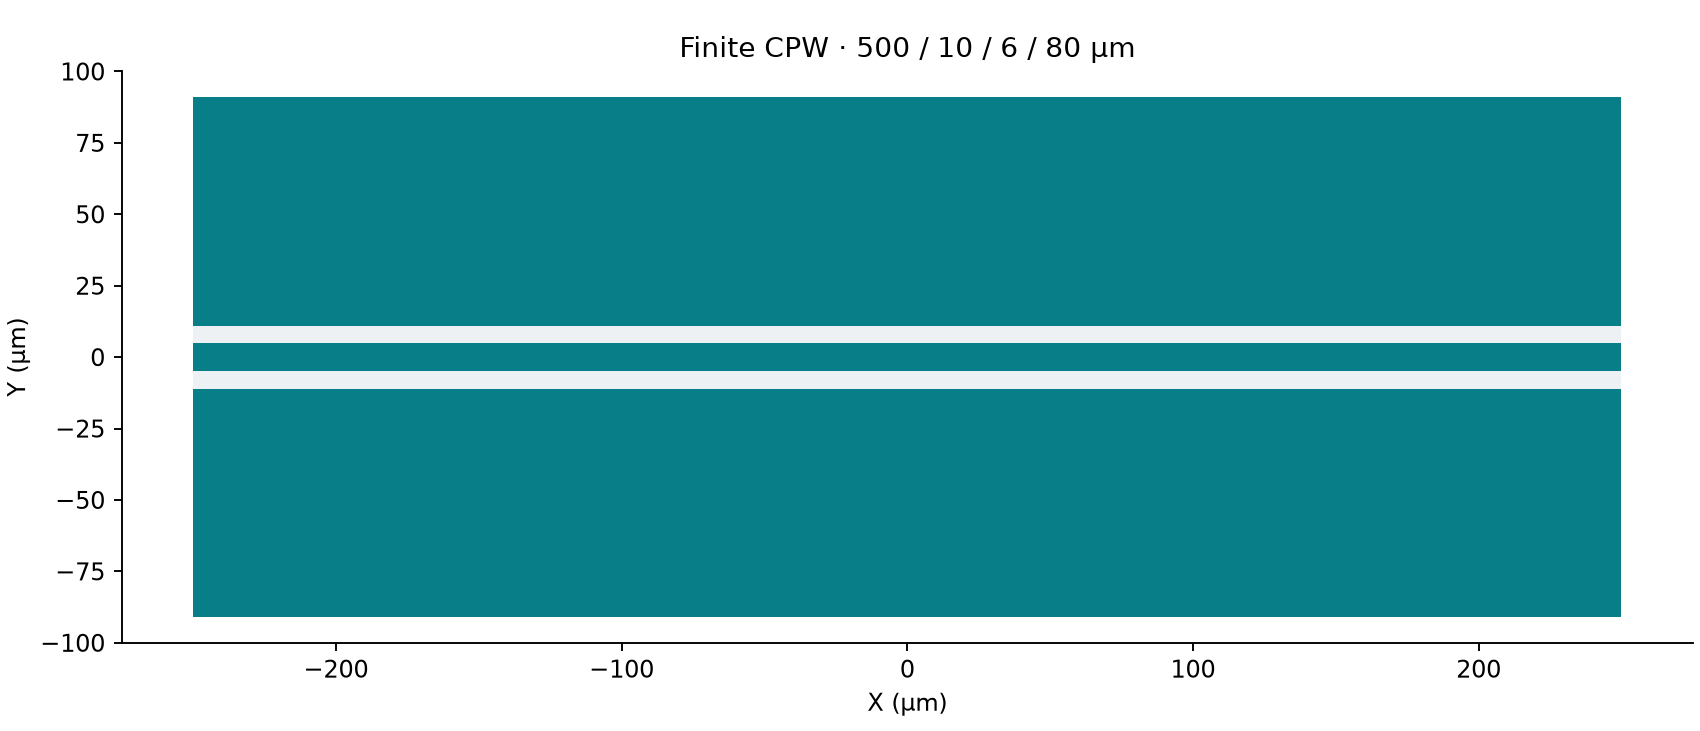

Extract AC R/L and capacitance from the finite-ground CPW. See the [Q3D
AC/RL requirements](../../../../simulation/requirements/q3d-acrl.html).
The public coupon is 500 µm long, with a 10 µm signal, 6 µm gaps and 80
µm grounds. This current-PDK case selects Al 100 nm on Si 500 µm,
explicitly replacing the prior Nb 200 nm model. Source-free body-v3
records mirror the coupon rectangles; `geometry_source=None` is
deliberate, not a helper-produced source binding.

Fresh construction uses the local shared-physical candidate, not a
published wheel. Retained results keep their original runtime
identities.

Published historical baseline:
[SCGSim](https://github.com/OrPenStrike/scgsim/tree/c9270c7e76e0b2df187dddde462079e00d410dd0).

## Setup and Imports

In [ ]:
from __future__ import annotations

import subprocess
import sys
from pathlib import Path
from uuid import uuid4

import gdsfactory as gf
from IPython.display import display
from scgsim.aedt import (
    AedtResources,
    MatrixRunControl,
    PdkMaterial,
    Q3dBodySpec,
    Q3dNetSpec,
    Q3dSpec,
    prepare_handoff,
    resolve_results,
)
from scgsim.geometry import (
    ApproximationProfile,
    PhysicalLayerDeclaration,
    interpret_physical_layers,
)

import orcapen_sc_pdk
from orcapen_sc_pdk.cells import finite_ground_cpw_coupon
from orcapen_sc_pdk.materials import get_material_records
from orcapen_sc_pdk.tech import get_single_die_layer_stack

## Setup and Run Controls

In [ ]:
WORKFLOW_ACTION = "run"  # AUTHORING_ONLY | prepare_handoff | prepare_only | run | analyze_handoff
RUN_ID = f"cpw_q3d_{uuid4().hex}"
OUTPUT_ROOT = Path.cwd() / ".artifacts" / "SCGSimExamples" / "CpwFiniteGround"
RUN_DIR = OUTPUT_ROOT / RUN_ID
RETURNED_RUN_DIR = None  # Set independently to an immutable returned-run directory.
SCGSIM_RUNTIME_SOURCE = "LOCAL_SHARED_PHYSICAL_CANDIDATE_UNCOMMITTED"
RESOURCES = AedtResources(cores=4, ram_limit_percent=30)
MODELING = "solid"
APPROXIMATION_PROFILE = ApproximationProfile(name=MODELING, revision="v1", parameters={})
SOLVE_AC_RL = True
# CPW trace length along X (um).
trace_length_um = 500.0
# Signal conductor width (um).
signal_width_um = 10.0
# Gap from signal to each ground conductor (um).
gap_um = 6.0
# Width of each ground conductor (um).
ground_width_um = 80.0
# AEDT version used for project generation.
aedt_version = "2024.2"
# AEDT project name.
project_name = RUN_ID
# AEDT design name.
design_name = "CpwFiniteGroundQ3d"
# Padding around the model in +X, -X, +Y, -Y, +Z, -Z directions (um).
region_padding_um = (0.0, 0.0, 100.0, 100.0, 1000.0, 1000.0)
# Matrix solve frequency (GHz).
frequency_ghz = 6.0
# Maximum adaptive passes.
maximum_passes = 3

## Create Simulation Component / Coupon

In [ ]:
if WORKFLOW_ACTION != "analyze_handoff":
    orcapen_sc_pdk.activate()
    gf.clear_cache()
    coupon = finite_ground_cpw_coupon(
        trace_length_um=trace_length_um,
        signal_width_um=signal_width_um,
        gap_um=gap_um,
        ground_width_um=ground_width_um,
    )
    layer_stack = get_single_die_layer_stack()
    material_records = get_material_records()
    # Process dimensions and materials are source-owned PDK facts, not case controls.
    metal_level = layer_stack.layers["D0_TOP_M1"]
    substrate_level = layer_stack.layers["D0_SUBSTRATE"]
    metal_zmin_um = metal_level.zmin
    metal_zmax_um = metal_level.zmin + metal_level.thickness
    substrate_zmin_um = substrate_level.zmin
    substrate_zmax_um = substrate_level.zmin + substrate_level.thickness
    display(
        {
            "metal": (metal_level.material, metal_zmin_um, metal_zmax_um),
            "substrate": (substrate_level.material, substrate_zmin_um, substrate_zmax_um),
            "units": "um",
        }
    )

## Initialize AEDT Project / App

In [ ]:
# Only the generated native runner owns an AEDT session.

## Import GDS and Build the HFSS/Q3D/Q2D Model

In [ ]:
if WORKFLOW_ACTION != "analyze_handoff":
    # Source-free body-v3 records mirror the four GDSFactory rectangles exactly.
    # Body IDs are authored identities, not guesses about native imported names.
    x = trace_length_um / 2
    s = signal_width_um / 2
    g = s + gap_um
    w = ground_width_um
    bodies = (
        Q3dBodySpec(
            "SignalBody",
            ((-x, -s), (x, -s), (x, s), (-x, s)),
            (),
            metal_zmin_um,
            metal_zmax_um,
            metal_level.material,
            "signal",
            "Signal",
            physical_layer_id=metal_level.info["physical_layer"]["physical_layer_id"],
        ),
        Q3dBodySpec(
            "GroundLeftBody",
            ((-x, g), (x, g), (x, g + w), (-x, g + w)),
            (),
            metal_zmin_um,
            metal_zmax_um,
            metal_level.material,
            "ground",
            "GroundLeft",
            physical_layer_id=metal_level.info["physical_layer"]["physical_layer_id"],
        ),
        Q3dBodySpec(
            "GroundRightBody",
            ((-x, -g - w), (x, -g - w), (x, -g), (-x, -g)),
            (),
            metal_zmin_um,
            metal_zmax_um,
            metal_level.material,
            "ground",
            "GroundRight",
            physical_layer_id=metal_level.info["physical_layer"]["physical_layer_id"],
        ),
        Q3dBodySpec(
            "SubstrateBody",
            ((-x, -g - w), (x, -g - w), (x, g + w), (-x, g + w)),
            (),
            substrate_zmin_um,
            substrate_zmax_um,
            substrate_level.material,
            "substrate",
            None,
            physical_layer_id=substrate_level.info["physical_layer"]["physical_layer_id"],
        ),
    )

## Geometry Verification

In [ ]:
if WORKFLOW_ACTION != "analyze_handoff":
    display(coupon)
    display({"bbox_um": str(coupon.dbbox())})

## Materials and Boundaries

In [ ]:
if WORKFLOW_ACTION != "analyze_handoff":
    material_records = get_material_records()
    materials = {
        material_id: PdkMaterial(
            material_id,
            material_records[material_id]["material_kind"],
            material_records[material_id]["is_superconducting"],
            material_records[material_id]["aedt_library_name"],
        )
        for material_id in ("vacuum", substrate_level.material, metal_level.material)
    }

## Ports / Nets / Excitations

In [ ]:
if WORKFLOW_ACTION != "analyze_handoff":
    # Net names, roles, object members, and terminal directions define Q3D excitations.
    nets = (
        # Net name, net role, member objects, and optional terminal object/directions.
        Q3dNetSpec("Signal", "Signal", ("SignalBody",), "SignalBody", "-X", "SignalBody", "+X"),
        Q3dNetSpec("GroundLeft", "Ground", ("GroundLeftBody",)),
        Q3dNetSpec("GroundRight", "Ground", ("GroundRightBody",)),
    )

## Simulation Setup

In [ ]:
if WORKFLOW_ACTION != "analyze_handoff":
    physical_layers = tuple(
        PhysicalLayerDeclaration.from_payload(level.info["physical_layer"])
        for level in (metal_level, substrate_level)
    )
    spec = Q3dSpec(
        modeling=APPROXIMATION_PROFILE.name,
        project_name=project_name,
        physical_layers=physical_layers,
        physical_representation=interpret_physical_layers(physical_layers, APPROXIMATION_PROFILE),
        design_name=design_name,
        materials=materials,
        vacuum_material_id="vacuum",
        bodies=bodies,
        nets=nets,
        geometry_source=None,
        solve_ac_rl=SOLVE_AC_RL,
        run_control=MatrixRunControl("Setup1", frequency_ghz, maximum_passes),
        region_padding_um=region_padding_um,
        aedt_version=aedt_version,
    )

## Simulation Configuration

In [ ]:
if WORKFLOW_ACTION != "analyze_handoff":
    display(spec)

## Solve and Export

In [ ]:
if WORKFLOW_ACTION in {"prepare_handoff", "prepare_only", "run"}:
    HANDOFF = prepare_handoff(spec=spec, output_dir=RUN_DIR, resources=RESOURCES)
    display(HANDOFF)
    if WORKFLOW_ACTION == "run":
        subprocess.run([str(HANDOFF.script_path)], cwd=HANDOFF.run_dir, check=True)

## Prepare-only native model inspection

Select `prepare_only` to build, read back, save and release the native
model without Analyze. This does not produce solved physics results.

In [ ]:
if WORKFLOW_ACTION == "prepare_only":
    from scgsim.aedt import resolve_prepared_model

    subprocess.run(
        [
            sys.executable,
            "-m",
            "scgsim.aedt.run",
            "--handoff",
            str(HANDOFF.metadata_path),
            "--execute",
            "--prepare-only",
        ],
        check=True,
    )
    display(resolve_prepared_model(HANDOFF.run_dir))

## Adaptive-Pass Convergence / Solver Diagnostics

In [ ]:
if WORKFLOW_ACTION in {"run", "analyze_handoff"}:
    result = resolve_results(
        HANDOFF.run_dir if WORKFLOW_ACTION == "run" else Path(RETURNED_RUN_DIR)
    )
    result.show_all_results(show_details=True)

## Results: Plots and Readable Tables

### Physics Analysis Results

In [ ]:
if WORKFLOW_ACTION in {"run", "analyze_handoff"}:
    display(result.physics_results())

### Simulation Performance / Benchmarks

In [ ]:
if WORKFLOW_ACTION in {"run", "analyze_handoff"}:
    display(result.simulation_benchmark())

## Save and Release AEDT

In [ ]:
if WORKFLOW_ACTION in {"run", "analyze_handoff"}:
    display({"project": result.project_path, "receipt": result.receipt_path})
elif WORKFLOW_ACTION in {"prepare_handoff", "prepare_only", "run"}:
    display(HANDOFF.archive_path)